# Phase calculation and comparison with theory for a single trajectory (CPU / Numba)

Estimate c, B, and the phases from a single trajectory of two coupled systems with noise. Run the cells from top to bottom.

This program provides sample code for calculating the spatial and temporal phases, as demonstrated in Secs. 2B and 3B in [Arai et al., arXiv:2604.23727](https://arxiv.org/abs/2604.23727).


While the paper uses data from multiple trajectories to calculate the phases, this sample program generates a single trajectory through an SPDE simulation and calculates the phases from that trajectory.



## 1. Setup
Run this notebook with `SampleCode/` as the working directory.

In [19]:
from pathlib import Path
import time
import json

import numpy as np
import matplotlib.pyplot as plt

from spde_cpu import simulate
from sample_io import load_precomputed_results
from scipy.interpolate import interp1d
from phase_analysis import (
    calculate_Theta, calculate_c, calculate_b, concatenate_theta_b,
    fit_B_function, calculate_Phi, get_common_time, solve_theory, wrap_period,
)
from sample_setup import initial_states_from_phases, integer_steps

%matplotlib inline

TEST_DIR = Path('.')
DATA_DIR = TEST_DIR / 'data'

## 2. Parameters
`T_END` is the final value of the rescaled time $\epsilon t$. `DT` is the integration time step, and `SAVE_INTERVAL` is the output sampling interval, both in physical time $t$.
Specify the initial phases using `Phi_i_over_L` (Φᵢ/L) and `Theta_i_over_pi` (Θᵢ/π). The spatial domain is `[-L, L]`, with `L=125`.

In [20]:
# Set to True to load and plot the complete saved results.
# Set to False to run the simulation and calculate new results.
loaddata = False

OUTPUT_DIR = TEST_DIR / 'output'

if loaddata:
    saved_settings = json.loads((OUTPUT_DIR / 'parameters.json').read_text())
    print("Saved trajectories, phases, and theoretical predictions will be loaded and plotted.")
    print("The simulation and analysis settings below will be replaced by the saved settings.")
    print(f"T_END = {saved_settings['t_end']}")
    print(f"SIGMA^2 = {saved_settings['sigma'] ** 2:g}")
    for name in ('Phi_1_over_L', 'Theta_1_over_pi', 'Phi_2_over_L', 'Theta_2_over_pi'):
        print(f"{name} = {saved_settings[name]}")
else:
    print("The SPDE simulation will run. Existing output files will be overwritten.")

The SPDE simulation will run. Existing output files will be overwritten.


In [21]:
T_END = 3.0            # Final rescaled time, epsilon * t;  #* For 3.0 runtime is approximately 4 hours.
SIGMA = 1e-5              # Noise amplitude; sigma**2 is the intensity. Set to 0 to disable noise.
Phi_1_over_L = 0.60       # System 1: Phi_1 / L (aligned with the grid)
Theta_1_over_pi = 0.0      # System 1: Theta_1 / pi (aligned with the grid)
Phi_2_over_L = 0.0         # System 2: Phi_2 / L
Theta_2_over_pi = 0.0      # System 2: Theta_2 / pi

In [22]:
DT = 0.01
SAVE_INTERVAL = 1.0
EPSILON = 1e-6
SECTION = 7.0            # Section for upward crossings used to define temporal phase
B_HARMONICS = 10         # Fourier order for B (cosine/sine terms, no constant term)
SEED = 12345

X0_PATH = DATA_DIR / 'X0_axes.csv'
COUPLING_PATH = DATA_DIR / 'MutualCouplingFunction_8193_axes.csv'
B_THEORY_PATH = DATA_DIR / 'B_theory.csv'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 3. Initial states
Start from
$$X_1=X_0(\Phi_1,\Theta_1),\qquad X_2=X_0(\Phi_2,\Theta_2).$$
Each phase is snapped to the nearest point on the periodic grid of the X0 data.

In [23]:
if not loaddata:
    rx = np.genfromtxt(X0_PATH, delimiter=',', names=True)['rx']
    DOMAIN_LENGTH = float(np.ptp(rx))
    L = DOMAIN_LENGTH / 2

    Phi_1, Theta_1 = Phi_1_over_L * L, Theta_1_over_pi * np.pi
    Phi_2, Theta_2 = Phi_2_over_L * L, Theta_2_over_pi * np.pi
    initial, rx, init_info = initial_states_from_phases(
        X0_PATH, Phi_1, Theta_1, Phi_2, Theta_2,
    )

## 4. Run the SPDE simulation or load saved data
Set `loaddata = True` to load the complete results in `output/`, including the saved phases and theoretical predictions. The saved parameters are restored, and no simulation or phase/theory calculations are performed. Set it to `False` to calculate new results.

In [24]:
if loaddata:
    saved_results = load_precomputed_results(
        OUTPUT_DIR, fallback_b_theory=DATA_DIR / 'B_theory.csv',
    )
    moments = saved_results['moments']
    parameters = saved_results['parameters']
    rx = saved_results['rx']
    DT = saved_results['dt']
    EPSILON = saved_results['epsilon']
    SIGMA = saved_results['sigma']
    SEED = saved_results['seed']
    SAVE_INTERVAL = saved_results['save_interval']
    DOMAIN_LENGTH = saved_results['domain_length']
    L = saved_results['L']
    T_END = saved_results['t_end']
    SECTION = saved_results['section']
    B_HARMONICS = saved_results['b_harmonics']
    simulation_seconds = float(parameters['simulation_seconds'])
    Phi_1, Theta_1 = float(parameters['Phi1_initial']), float(parameters['Theta1_initial'])
    Phi_2, Theta_2 = float(parameters['Phi2_initial']), float(parameters['Theta2_initial'])
    Phi_1_over_L = float(parameters['Phi_1_over_L'])
    Theta_1_over_pi = float(parameters['Theta_1_over_pi'])
    Phi_2_over_L = float(parameters['Phi_2_over_L'])
    Theta_2_over_pi = float(parameters['Theta_2_over_pi'])
else:
    T_PHYSICAL = T_END / EPSILON
    N_STEPS = integer_steps(T_PHYSICAL, DT, 'T_END / EPSILON')
    SAVE_STRIDE = integer_steps(SAVE_INTERVAL, DT, 'SAVE_INTERVAL')
    started = time.perf_counter()
    moments = simulate(
        initial, rx, DT, N_STEPS, SAVE_STRIDE,
        epsilon=EPSILON, sigma=SIGMA, seed=SEED, progress=True,
    )
    simulation_seconds = time.perf_counter() - started

SPDE:   0%|          | 0.00/300M [00:00<?, ?step/s]

In [25]:
if not loaddata:
    np.savetxt(
        OUTPUT_DIR / 'trajectory.csv',
        np.column_stack((
            moments['t'], moments['U1_bar'], moments['V1_bar'],
            moments['U2_bar'], moments['V2_bar'],
            moments['A1_tilde'].real, moments['A1_tilde'].imag,
            moments['A2_tilde'].real, moments['A2_tilde'].imag,
        )),
        delimiter=',', fmt='%.17g', comments='',
        header='t,U1_bar,V1_bar,U2_bar,V2_bar,A1_tilde_real,A1_tilde_imag,A2_tilde_real,A2_tilde_imag',
    )
    np.savetxt(
        OUTPUT_DIR / 'final_state.csv',
        np.column_stack((rx[:-1], *moments['final_state'].reshape(4, -1))),
        delimiter=',', fmt='%.17g', header='rx,U1,V1,U2,V2', comments='',
    )
    parameters = {
        'dt': DT, 'epsilon': EPSILON, 'sigma': SIGMA, 'seed': SEED, 't_end': T_END,
        'save_interval': SAVE_INTERVAL, 'domain_length': DOMAIN_LENGTH,
        'Phi1_initial': init_info['phi1'], 'Theta1_initial': init_info['theta1'],
        'Phi2_initial': init_info['phi2'], 'Theta2_initial': init_info['theta2'],
        'Phi_1_over_L': Phi_1_over_L, 'Theta_1_over_pi': Theta_1_over_pi,
        'Phi_2_over_L': Phi_2_over_L, 'Theta_2_over_pi': Theta_2_over_pi,
        'simulation_seconds': simulation_seconds,
    }


FileNotFoundError: [Errno 2] No such file or directory: 'output/trajectory.csv'

## 5. Phase calculation

### 5.1 Calculate Θ

In [ ]:
t = moments['t']
if loaddata:
    Theta1 = saved_results['phase']['Theta1']
    Theta2 = saved_results['phase']['Theta2']
    t1 = t2 = saved_results['phase']['t']
else:
    Theta1, mask1 = calculate_Theta(moments['U1_bar'], t, section=SECTION)
    Theta2, mask2 = calculate_Theta(moments['U2_bar'], t, section=SECTION)
    t1, t2 = t[mask1], t[mask2]

### 5.2 Estimate the translation speed c

In [ ]:
params = {'L': L}
if loaddata:
    c1, c2 = saved_results['c1'], saved_results['c2']
else:
    c1 = calculate_c(moments['A1_tilde'], moments['U1_bar'], t, params, section=SECTION)
    c2 = calculate_c(moments['A2_tilde'], moments['U2_bar'], t, params, section=SECTION)
print(f'c1 = {c1:.8g}')
print(f'c2 = {c2:.8g}')

c1 = 0.043043391
c2 = 0.043067905


### 5.3 Calculate b for each cycle

In [ ]:
if not loaddata:
    b1 = calculate_b(moments['A1_tilde'][mask1], Theta1, t1,
                     {'L': L, 'c': c1})
    b2 = calculate_b(moments['A2_tilde'][mask2], Theta2, t2,
                     {'L': L, 'c': c2})

### 5.4 Estimate the periodic correction function B

In [ ]:
if loaddata:
    B1, B2 = saved_results['B1'], saved_results['B2']
else:
    bx1, by1 = concatenate_theta_b(b1)
    bx2, by2 = concatenate_theta_b(b2)
    B1 = fit_B_function(Theta=bx1, B=by1, M=B_HARMONICS)
    B2 = fit_B_function(Theta=bx2, B=by2, M=B_HARMONICS)

### 5.5 Calculate Φ

In [ ]:
if loaddata:
    Phi1 = saved_results['phase']['Phi1']
    Phi2 = saved_results['phase']['Phi2']
else:
    Bfunc1 = interp1d(B1['Bx'], B1['By'], kind='linear')
    Bfunc2 = interp1d(B2['Bx'], B2['By'], kind='linear')
    Phi1 = calculate_Phi(moments['A1_tilde'][mask1], Theta1, Bfunc1, params)
    Phi2 = calculate_Phi(moments['A2_tilde'][mask2], Theta2, Bfunc2, params)

### 5.6 Calculate phase differences at common times

In [ ]:
if loaddata:
    t_phase = saved_results['phase']['t']
    delta_phi = saved_results['phase']['delta_phi']
    delta_theta = saved_results['phase']['delta_theta']
else:
    common1, common2 = get_common_time(t1, t2)
    t_phase = t1[common1]
    delta_phi = wrap_period(Phi1[common1] - Phi2[common2], DOMAIN_LENGTH)
    delta_theta = wrap_period(Theta1[common1] - Theta2[common2], 2 * np.pi)

### 5.7 Observed time series

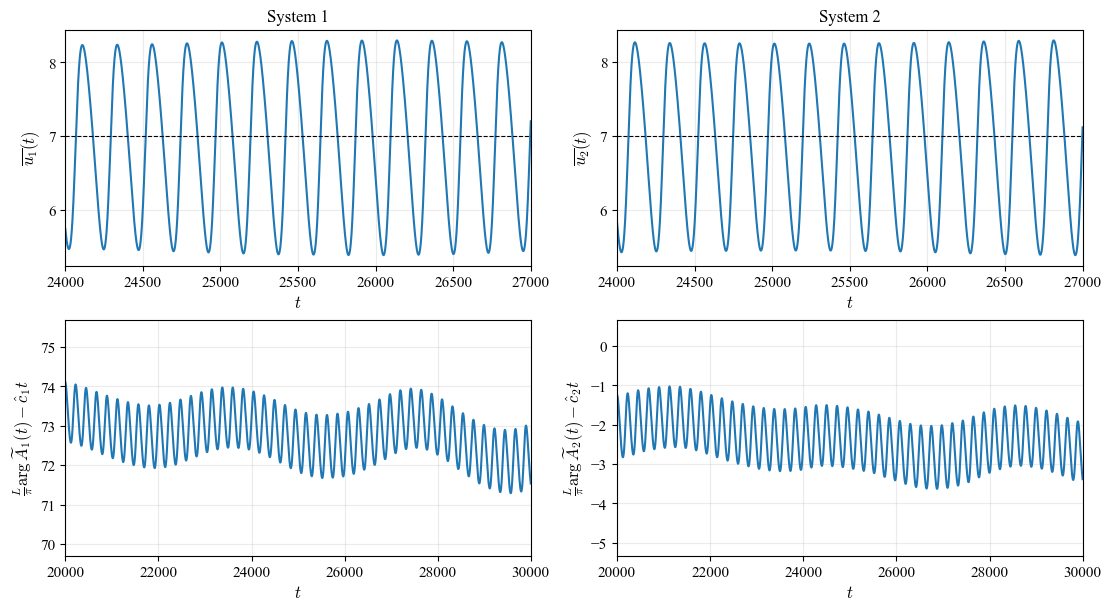

In [ ]:
t = moments['t']
arg_u = (24000 <= t) & (t <= 27000)
arg_a = (20000 <= t) & (t <= 30000)
timeseries_fig, axes = plt.subplots(2, 2, figsize=(7, 4), sharex='row', constrained_layout=True)
for j, (i, ci) in enumerate(((1, c1), (2, c2))):
    angle_a = np.unwrap(np.angle(moments[f'A{i}_tilde']))
    drift_removed = (L / np.pi) * angle_a[arg_a] - ci * t[arg_a]
    axes[0, j].plot(t[arg_u], moments[f'U{i}_bar'][arg_u])
    axes[0, j].set_xlim(24000, 27000)
    axes[0, j].axhline(SECTION, color='black', ls='--', lw=0.8)
    axes[0, j].set_ylabel(fr'$\overline{{u_{i}}}(t)$')
    axes[0, j].set_yticks([6, 7, 8])
    axes[0, j].set_title(f'System {i}')
    axes[1, j].plot(t[arg_a], drift_removed)
    axes[1, j].set_xlim(20000, 30000)
    center = (drift_removed.min() + drift_removed.max()) / 2
    axes[1, j].set_ylim(center - 3, center + 3)
    axes[1, j].set_ylabel(fr'$\frac{{L}}{{\pi}}\arg\widetilde A_{i}(t)-\hat c_{i}t$')
for ax in axes.flat:
    ax.set_xlabel(r'$t$')
    ax.grid(alpha=0.25)
plt.show()

### 5.8 Compare B with the theoretical curve

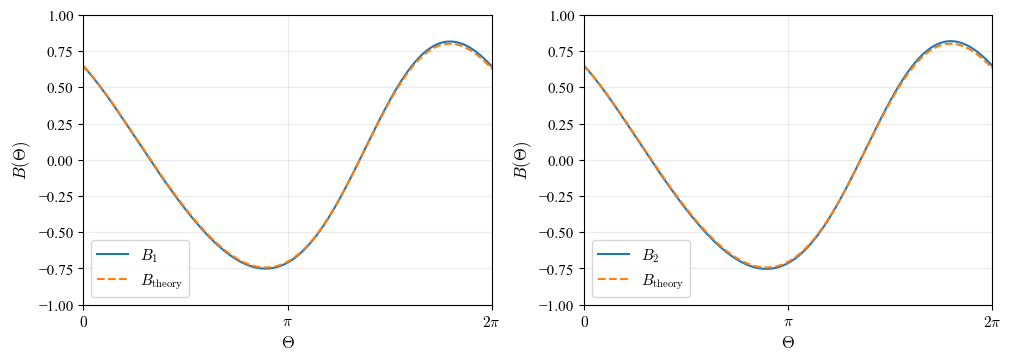

In [ ]:
if loaddata:
    b_theory = saved_results['b_theory']
else:
    b_theory = np.genfromtxt(B_THEORY_PATH, delimiter=',', names=True)
b_fig, axes = plt.subplots(1, 2, figsize=(7, 3), constrained_layout=True)
for i, (ax, Bi) in enumerate(zip(axes, (B1, B2)), start=1):
    ax.plot(Bi['Bx'], Bi['By'], label=fr'$B_{i}$')
    ax.plot(b_theory['theta'], b_theory['B_theory'], '--', label=r'$B_{\mathrm{theory}}$')
    ax.set(xlabel=r'$\Theta$', ylabel=r'$B(\Theta)$', xlim=(0, 2 * np.pi), ylim=(-1, 1))
    ax.set_xticks([0, np.pi, 2 * np.pi], [r'$0$', r'$\pi$', r'$2\pi$'])
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## 6. Theoretical prediction
For a new calculation, solve the averaged phase equations using the measured initial phase differences. When `loaddata = True`, use the theoretical prediction saved in `phase_comparison.csv`.

In [ ]:
if loaddata:
    theory = np.vstack((saved_results['phase']['theory_delta_phi'],
                        saved_results['phase']['theory_delta_theta']))
else:
    theory = solve_theory(
        t_phase, [delta_phi[0], delta_theta[0]],
        COUPLING_PATH, EPSILON, DOMAIN_LENGTH,
    )

## 7. Time series of phase differences
Phase differences are defined as system 1 minus system 2. The horizontal axis shows $\epsilon t$.

$$\Delta \Phi= \Phi_1 - \Phi_2$$

$$\Delta \Theta= \Theta_1 - \Theta_2$$


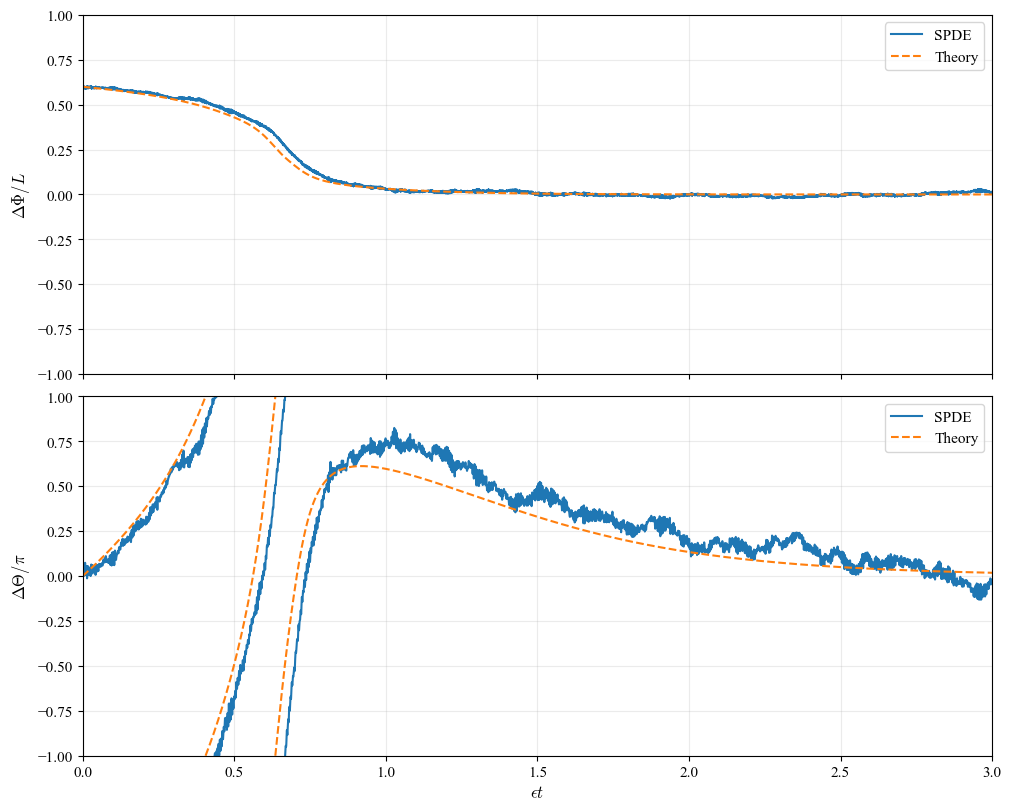

In [ ]:
comparison_fig, axes = plt.subplots(2, 1, figsize=(7, 4), sharex=True, constrained_layout=True)
x = saved_results['phase']['eps_t'] if loaddata else EPSILON * t_phase

for i, (observed, period, scale, label) in enumerate((
    (delta_phi, DOMAIN_LENGTH, L, r'$\Delta\Phi/L$'),
    (delta_theta, 2 * np.pi, np.pi, r'$\Delta\Theta/\pi$'),
)):
    for y, name, style in (
        (observed, 'SPDE', '-'),
        (wrap_period(theory[i], period), 'Theory', '--'),
    ):
        # Do not connect lines across periodic boundaries
        jumps = np.flatnonzero(np.abs(np.diff(y)) > period / 2) + 1
        axes[i].plot(np.insert(x, jumps, np.nan), np.insert(y / scale, jumps, np.nan),
                     style, label=name)
    axes[i].set_ylabel(label)
    axes[i].legend()
    axes[i].grid(alpha=0.25)
    axes[i].set_xlim(0, T_END)
    axes[0].set_ylim(-1, 1)
    axes[1].set_ylim(-1, 1)
axes[-1].set_xlabel(r'$\epsilon t$')
plt.show()

## 8. Save results
When `loaddata = False`, save numerical data as CSV files, the run settings as `parameters.json`, and figures as PNG files in `output/`. Existing files with the same names will be overwritten. When `loaddata = True`, display the saved results without overwriting the files.

In [ ]:
if not loaddata:
    np.savetxt(
        OUTPUT_DIR / 'phase_comparison.csv',
        np.column_stack((
            t_phase, EPSILON * t_phase, delta_phi, delta_theta, theory[0], theory[1],
            Phi1[common1], Theta1[common1], Phi2[common2], Theta2[common2],
        )),
        delimiter=',', fmt='%.17g', comments='',
        header='t,eps_t,delta_phi,delta_theta,theory_delta_phi,theory_delta_theta,Phi1,Theta1,Phi2,Theta2',
    )
    np.savetxt(
        OUTPUT_DIR / 'B_estimated.csv', np.column_stack((B1['Bx'], B1['By'], B2['By'])),
        delimiter=',', fmt='%.17g', header='theta,B1,B2', comments='',
    )
    np.savetxt(
        OUTPUT_DIR / 'B_coefficients.csv',
        np.column_stack((np.arange(1, B_HARMONICS + 1),
                         B1['alpha'], B1['beta'], B2['alpha'], B2['beta'])),
        delimiter=',', fmt='%.17g', header='n,cos1,sin1,cos2,sin2', comments='',
    )
    np.savetxt(
        OUTPUT_DIR / 'B_samples.csv',
        np.column_stack((np.repeat([1, 2], [len(bx1), len(bx2)]),
                         np.concatenate((bx1, bx2)), np.concatenate((by1, by2)))),
        delimiter=',', fmt='%.17g', header='system,theta,b', comments='',
    )
    np.savetxt(
        OUTPUT_DIR / 'B_theory.csv',
        np.column_stack((b_theory['theta'], b_theory['B_theory'])),
        delimiter=',', fmt='%.17g', header='theta,B_theory', comments='',
    )
    parameters.update({
        'c1': c1, 'c2': c2, 'section': SECTION,
        'b_method': 'estimated', 'b_source': 'estimated_from_trajectory',
        'b_harmonics': B_HARMONICS, 'b_trim_cycles': 1,
        'b_offset1': B1['offset'], 'b_offset2': B2['offset'],
        'b_fit_cycles1': len(b1), 'b_fit_cycles2': len(b2),
    })

    timeseries_fig.savefig(OUTPUT_DIR / 'timeseries.png', dpi=180)
    comparison_fig.savefig(OUTPUT_DIR / 'comparison.png', dpi=180)
    b_fig.savefig(OUTPUT_DIR / 'B_estimation.png', dpi=180)
    with (OUTPUT_DIR / 'parameters.json').open('w', encoding='utf-8') as stream:
        json.dump(parameters, stream, indent=2, default=float, allow_nan=False)


Main results: `moments` (trajectory), `Theta1`, `Theta2`, `Phi1`, and `Phi2` (phases), `c1` and `c2` (estimated translation speeds), `B1` and `B2` (estimated periodic correction functions), and `theory` (theoretical prediction).